# 1. 加噪过程

In [2]:
import math
import torch
import matplotlib.pyplot as plt
import numpy as np

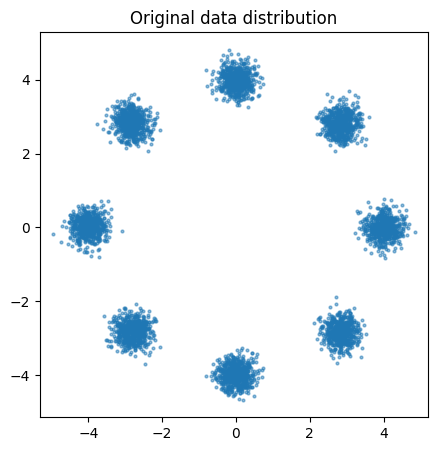

In [3]:
# 创建一个具有8个模式的二维数据分布
def sample_data(n, device="cpu"):
    labels = torch.randint(
        0, 8, (n,),
        device=device
    )

    angles = labels * (2 * math.pi / 8)

    centers = torch.stack([
        4 * torch.cos(angles),
        4 * torch.sin(angles),
    ], dim=1)

    return centers + 0.25 * torch.randn(
        n, 2,
        device=device
    )


x0 = sample_data(5000)

plt.figure(figsize=(5, 5))
plt.scatter(x0[:, 0], x0[:, 1], s=4, alpha=0.5)
plt.axis("equal")
plt.title("Original data distribution")
plt.show()

In [4]:
# 生成噪声强度
T = 1000

beta = torch.linspace(1e-4, 0.02, T) # 生成每个时间步的噪声强度
alpha = 1.0 - beta # 现在alpha是信号强度
alpha_bar = torch.cumprod(alpha, dim=0) # 累积积

print("alpha_bar at beginning:", alpha_bar[0].item())
print("alpha_bar at end:", alpha_bar[-1].item())

alpha_bar at beginning: 0.9998999834060669
alpha_bar at end: 4.035830352222547e-05


In [5]:
# 实现加噪
def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    # 确保噪声日程和数据在同一设备
    schedule = alpha_bar.to(x0.device)

    if isinstance(t, int):
        # 单个时间：标量 -> [1, 1]
        # 同一个系数用于整批样本
        alpha_bar_t = schedule[t].reshape(1, 1)

    else:
        t = torch.as_tensor(
            t,
            device=x0.device,
            dtype=torch.long,
        )

        if t.ndim == 0:
            # 零维 tensor，同样作为单个时间
            alpha_bar_t = schedule[t].reshape(1, 1)
        else:
            # 一批时间：[batch_size] -> [batch_size, 1]
            alpha_bar_t = schedule[t].reshape(-1, 1)

    xt = (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(1.0 - alpha_bar_t) * noise
    )

    return xt

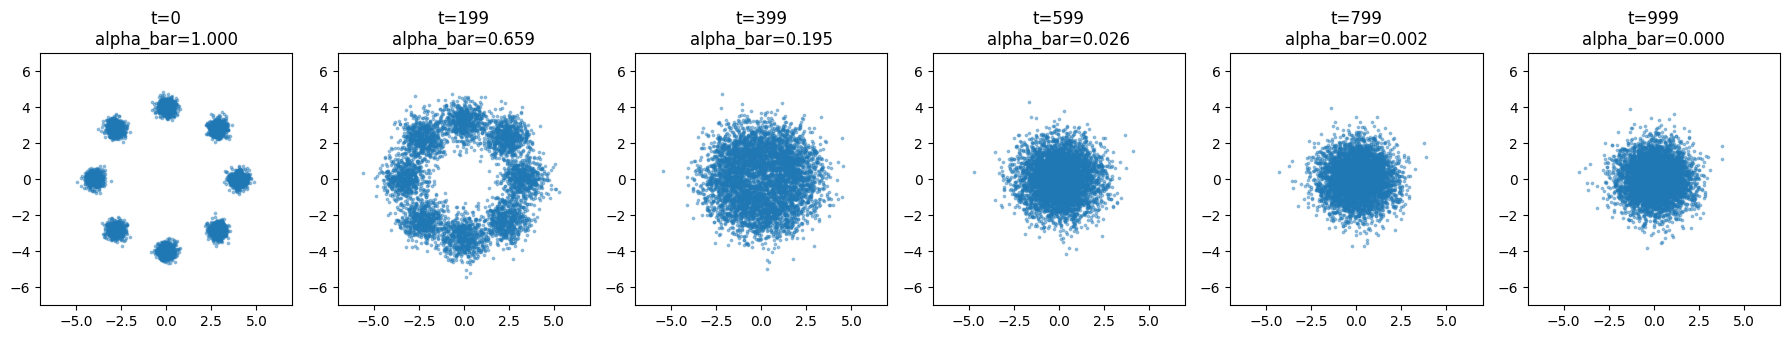

In [6]:
# 可视化加噪过程
noise = torch.randn_like(x0)

timesteps = list(map(int, np.linspace(0, T-1, 6)))

fig, axes = plt.subplots(
    1, len(timesteps),
    figsize=(18, 4)
)

for ax, t in zip(axes, timesteps):
    xt = q_sample(x0, t, noise) # t时刻的数据分布

    ax.scatter(
        xt[:, 0],
        xt[:, 1],
        s=3,
        alpha=0.4,
    )

    ax.set_title(
        f"t={t}\n"
        f"alpha_bar={alpha_bar[t]:.3f}"
    )
    ax.set_xlim(-7, 7)
    ax.set_ylim(-7, 7)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

# 2. 用来预测噪声的模型

In [7]:
import torch.nn as nn

In [8]:
# 时间编码，用于将t编码为一个向量
class TimeEmbedding(nn.Module):
    def __init__(self, dim=32):
        super().__init__()

        half_dim = dim // 2

        frequencies = torch.exp(
            torch.linspace(
                math.log(1.0),
                math.log(1000.0),
                half_dim,
            )
        )

        self.register_buffer(
            "frequencies",
            frequencies,
        )

    def forward(self, t):
        # 把时间归一化到 [0, 1]
        t = t.float() / (T - 1)

        angles = (
            2 * math.pi
            * t[:, None]
            * self.frequencies[None, :]
        )

        return torch.cat([
            torch.sin(angles),
            torch.cos(angles),
        ], dim=1)

In [9]:
# 噪声预测网络，输入x_t, t , 输出二维噪音
class NoisePredictor(nn.Module):
    def __init__(self, time_dim=32):
        super().__init__()

        self.time_embedding = TimeEmbedding(
            dim=time_dim
        )

        self.network = nn.Sequential(
            nn.Linear(2 + time_dim, 128),
            nn.SiLU(),

            nn.Linear(128, 128),
            nn.SiLU(),

            nn.Linear(128, 128),
            nn.SiLU(),

            nn.Linear(128, 2),
        )

    def forward(self, xt, t):
        time_features = self.time_embedding(t)

        inputs = torch.cat([
            xt,
            time_features,
        ], dim=1)

        return self.network(inputs)

# 3. 训练噪声网络

In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = NoisePredictor().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=2e-3,
)

T = 1000

beta = torch.linspace(1e-4, 0.02, T, device=device) # 生成每个时间步的噪声强度
alpha = 1.0 - beta # 现在alpha是信号强度
alpha_bar = torch.cumprod(alpha, dim=0) # 累积积

In [11]:
training_steps = 10000
batch_size = 256

loss_history = []

model.train()

for step in range(training_steps):
    # 1. 在模型所在设备上生成真实数据
    x0 = sample_data(
        batch_size,
        device=device,
    )

    # 2. 在相同设备上生成时间
    t = torch.randint(
        0,
        T,
        (batch_size,),
        device=device,
        dtype=torch.long,
    )

    # 3. noise 自动与 x0 位于相同设备
    noise = torch.randn_like(x0)

    # 4. 根据当前 x0、t、noise 构造新的 xt
    xt = q_sample(x0, t, noise)

    # 首次迭代检查设备
    if step == 0:
        print("model:", next(model.parameters()).device)
        print("x0:", x0.device)
        print("t:", t.device)
        print("noise:", noise.device)
        print("xt:", xt.device)

    # 5. 网络预测噪声
    predicted_noise = model(xt, t)

    # 6. 均方误差
    loss = torch.mean(
        (predicted_noise - noise) ** 2
    )

    # 7. 参数更新
    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0,
    )

    optimizer.step()

    loss_history.append(loss.item())

    if (step + 1) % 1000 == 0:
        print(
            f"step={step + 1}, "
            f"loss={loss.item():.4f}"
        )

model: cuda:0
x0: cuda:0
t: cuda:0
noise: cuda:0
xt: cuda:0
step=1000, loss=0.3862
step=2000, loss=0.3395
step=3000, loss=0.3148
step=4000, loss=0.3160
step=5000, loss=0.2549
step=6000, loss=0.3514
step=7000, loss=0.2793
step=8000, loss=0.3372
step=9000, loss=0.3117
step=10000, loss=0.2967


# 4. 查看训练效果

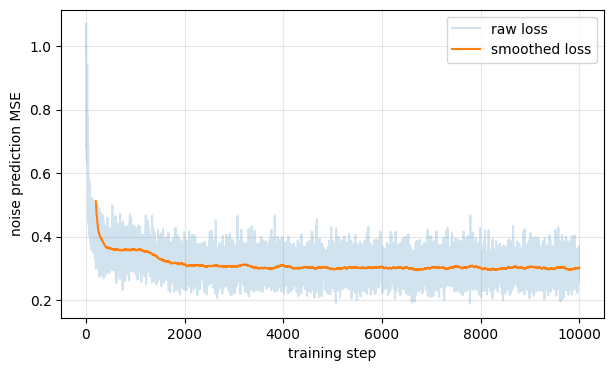

In [12]:
# 损失
import numpy as np
import matplotlib.pyplot as plt

loss_array = np.array(loss_history)

window = 200

smoothed_loss = np.convolve(
    loss_array,
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(7, 4))
plt.plot(
    loss_array,
    alpha=0.2,
    label="raw loss",
)
plt.plot(
    np.arange(window - 1, len(loss_array)),
    smoothed_loss,
    label="smoothed loss",
)

plt.xlabel("training step")
plt.ylabel("noise prediction MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. DDPM采样

In [13]:
# 预先计算反向方差
alpha_bar_previous = torch.cat([
    torch.ones(1, device=device),
    alpha_bar[:-1],
])

posterior_variance = (
    beta
    * (1.0 - alpha_bar_previous)
    / (1.0 - alpha_bar)
)

print(
    "first posterior variance:",
    posterior_variance[0].item()
)

first posterior variance: 0.0


In [14]:
# 采样
@torch.no_grad()
def sample_ddpm(
    model,
    n_samples=5000,
):
    model.eval()

    # 从标准高斯噪声开始
    x = torch.randn(
        n_samples,
        2,
        device=device,
    )

    snapshots = {
        T: x.detach().cpu()
    }

    save_times = {
        3 * T // 4,
        T // 2,
        T // 4,
        0,
    }

    for t_index in reversed(range(T)):
        t = torch.full(
            (n_samples,), # size
            t_index, # full_value
            device=device,
            dtype=torch.long,
        )

        # 1. 预测当前累计噪声
        predicted_noise = model(x, t)

        # 2. 计算反向分布均值
        mean = (
            x
            - beta[t_index]
            / torch.sqrt(
                1.0 - alpha_bar[t_index]
            )
            * predicted_noise
        ) / torch.sqrt(alpha[t_index])

        # 3. 从反向高斯分布采样
        if t_index > 0:
            z = torch.randn_like(x) # 高斯分布

            variance = posterior_variance[
                t_index
            ].clamp(min=1e-20) # 采样系数

            x = (
                mean
                + torch.sqrt(variance) * z
            )
        else:
            # 最后一步不加入随机噪声
            x = mean

        if t_index in save_times:
            snapshots[t_index] = (
                x.detach().cpu()
            )

    return x.detach().cpu(), snapshots

generated, snapshots = sample_ddpm(
    model,
    n_samples=5000,
)

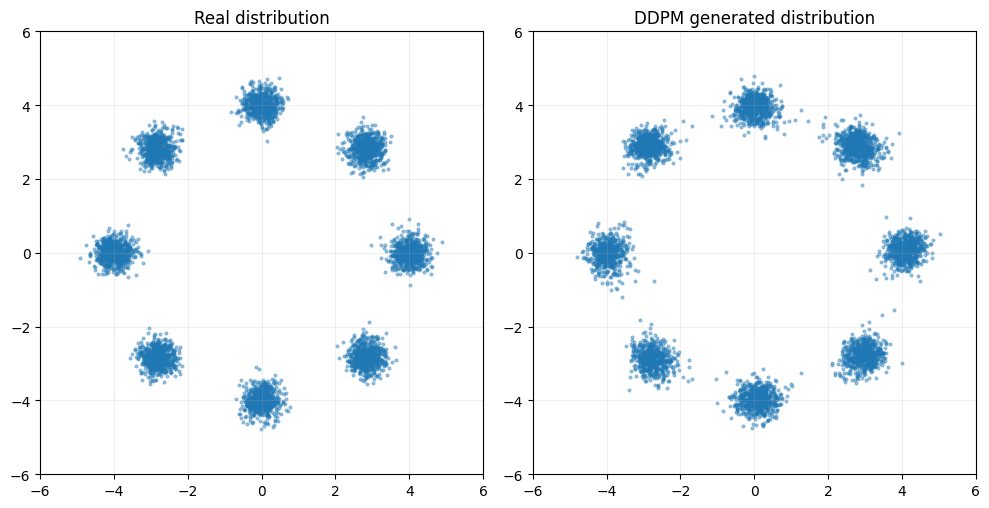

In [15]:
# 对比生成和真实数据
real = sample_data(
    5000,
    device="cpu",
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5),
)

axes[0].scatter(
    real[:, 0],
    real[:, 1],
    s=4,
    alpha=0.4,
)
axes[0].set_title("Real distribution")

axes[1].scatter(
    generated[:, 0],
    generated[:, 1],
    s=4,
    alpha=0.4,
)
axes[1].set_title("DDPM generated distribution")

for ax in axes:
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

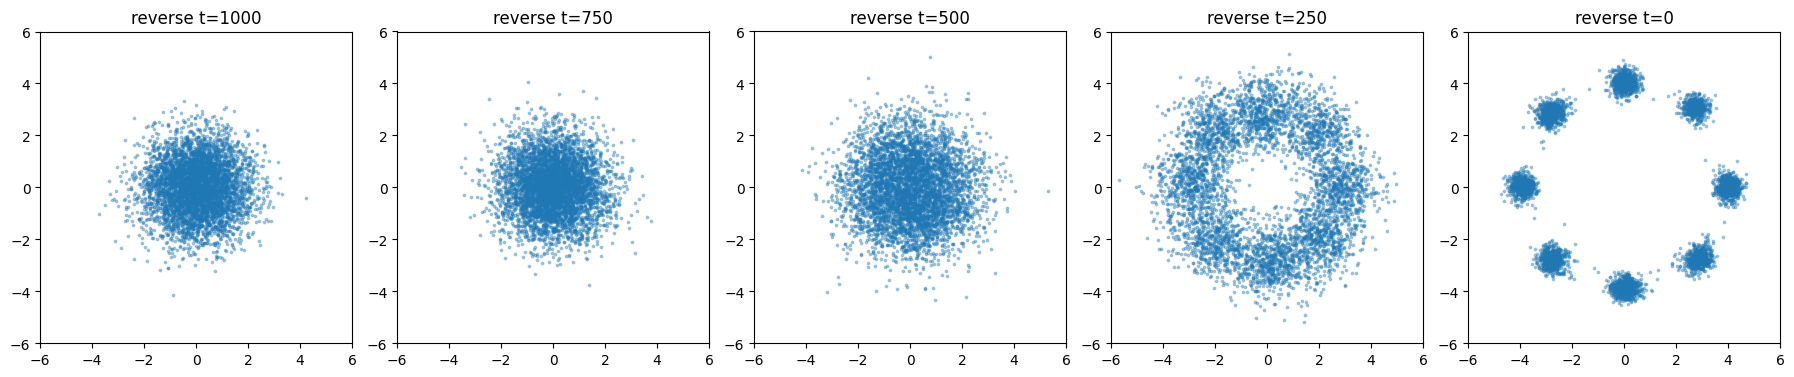

In [ ]:
# 观察DDPM的学习过程，从原始分布逐渐学习到目标分布
display_times = [
    T,
    3 * T // 4,
    T // 2,
    T // 4,
    0,
]

fig, axes = plt.subplots(
    1,
    len(display_times),
    figsize=(18, 4),
)

for ax, time_value in zip(
    axes,
    display_times,
):
    points = snapshots[time_value]

    ax.scatter(
        points[:, 0],
        points[:, 1],
        s=3,
        alpha=0.35,
    )

    ax.set_title(
        f"reverse t={time_value}"
    )
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

# 6.DDIM采样
观察同一个模型，但是可以采用不同的采样方式

## 6.1 确定性DDIM

In [16]:
@torch.no_grad()
def sample_ddim(
    model,
    n_samples=5000,
    num_steps=50,
    initial_noise=None,
):
    """
    确定性 DDIM 采样，eta=0。

    num_steps:
        实际调用模型的次数。

    initial_noise:
        可传入固定的初始噪声，
        用于比较不同采样步数。
    """
    model.eval()

    if not 1 <= num_steps <= T:
        raise ValueError(
            f"num_steps must be in [1, {T}]"
        )

    if initial_noise is None:
        x = torch.randn(
            n_samples,
            2,
            device=device,
        )
    else:
        x = initial_noise.clone().to(device)
        n_samples = x.shape[0]

    # 例如 num_steps=5：
    # [999, 749, 499, 249, 0]
    timesteps = torch.linspace(
        T - 1,
        0,
        num_steps,
        device=device,
    ).long()

    # 避免取整后产生重复时间
    timesteps = torch.unique_consecutive(
        timesteps
    )

    timestep_list = timesteps.tolist()

    for index, t_index in enumerate(
        timestep_list
    ):
        t = torch.full(
            (n_samples,),
            t_index,
            device=device,
            dtype=torch.long,
        )

        # 1. 网络预测噪声
        predicted_noise = model(x, t)

        alpha_bar_t = alpha_bar[t_index]

        # 2. 估计干净样本 x0
        predicted_x0 = (
            x
            - torch.sqrt(
                1.0 - alpha_bar_t
            ) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        # 当前已经是最后一个时间
        if index == len(timestep_list) - 1:
            x = predicted_x0
            break

        # 下一个更小的时间 s
        next_t_index = timestep_list[
            index + 1
        ]

        alpha_bar_s = alpha_bar[
            next_t_index
        ]

        # 3. 确定性地构造 xs
        x = (
            torch.sqrt(alpha_bar_s)
            * predicted_x0
            + torch.sqrt(
                1.0 - alpha_bar_s
            ) * predicted_noise
        )

    return x.detach().cpu()

In [17]:
# 采样
generated_ddim_100 = sample_ddim(
    model,
    n_samples=5000,
    num_steps=100,
)

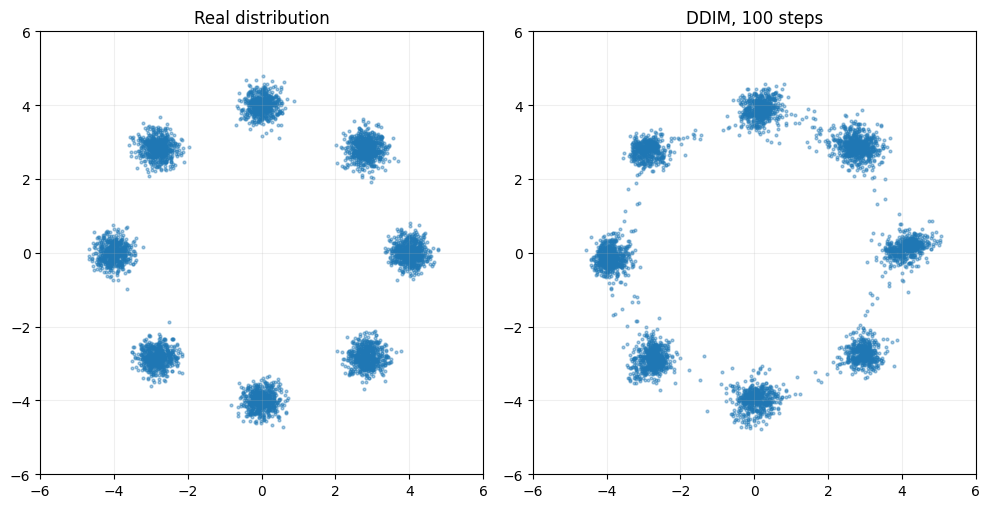

In [18]:
# 可视化
real = sample_data(
    5000,
    device="cpu",
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5),
)

axes[0].scatter(
    real[:, 0],
    real[:, 1],
    s=4,
    alpha=0.4,
)
axes[0].set_title("Real distribution")

axes[1].scatter(
    generated_ddim_100[:, 0],
    generated_ddim_100[:, 1],
    s=4,
    alpha=0.4,
)
axes[1].set_title("DDIM, 100 steps")

for ax in axes:
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 比较DDIM不同步数影响

In [19]:
initial_noise = torch.randn(
    5000,
    2,
    device=device,
)

generated_ddim_1000 = sample_ddim(
    model,
    num_steps=1000,
    initial_noise=initial_noise,
)

generated_ddim_100 = sample_ddim(
    model,
    num_steps=100,
    initial_noise=initial_noise,
)

generated_ddim_20 = sample_ddim(
    model,
    num_steps=20,
    initial_noise=initial_noise,
)

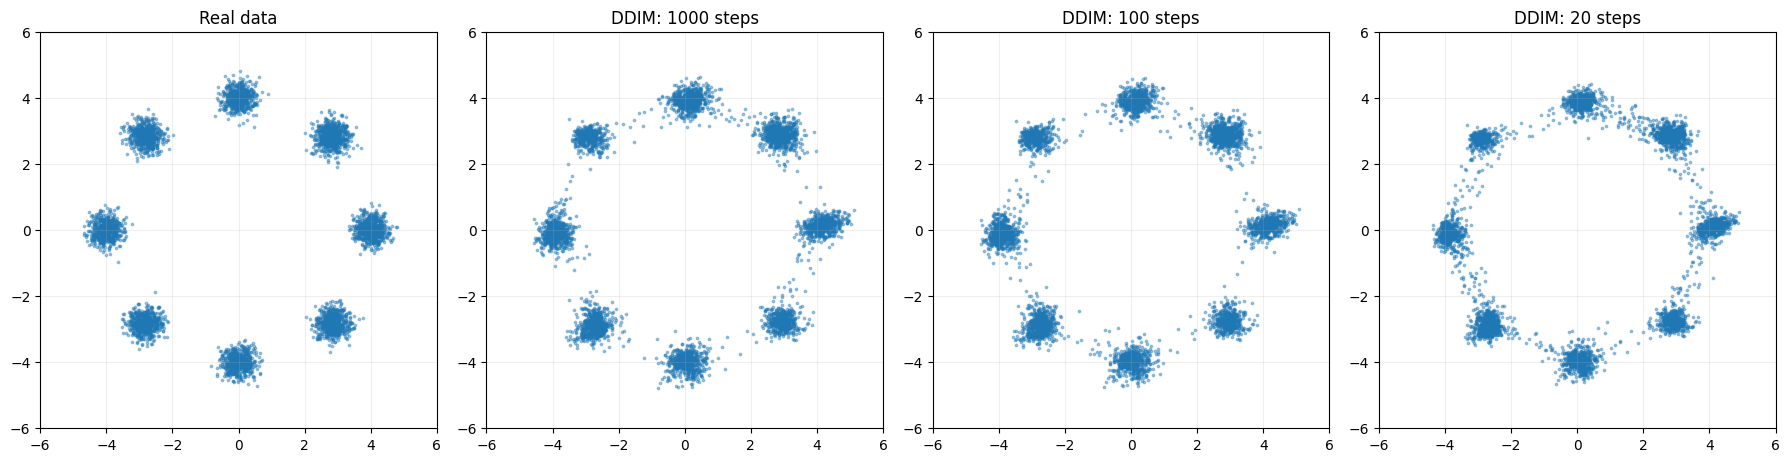

In [21]:
fig, axes = plt.subplots(
    1,
    4,
    figsize=(18, 4.5),
)

datasets = [
    real,
    generated_ddim_1000,
    generated_ddim_100,
    generated_ddim_20,
]

titles = [
    "Real data",
    "DDIM: 1000 steps",
    "DDIM: 100 steps",
    "DDIM: 20 steps",
]

for ax, points, title in zip(
    axes,
    datasets,
    titles,
):
    ax.scatter(
        points[:, 0],
        points[:, 1],
        s=3,
        alpha=0.4,
    )

    ax.set_title(title)
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()